# SØK2012 Behavioural Economics – Term Paper 2026

The formal derivations are handwritten and attached at the end of this PDF.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8a85"
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})


def pct(x):
    # Show 1 decimal, or more if needed so that e.g. 99.97 % doesn't show up as 100.0 %
    for d in (1, 2, 3, 4):
        s = f"{100 * x:.{d}f}"
        if x >= 1 or float(s) < 100:
            return s + " %"
    return s + " %"

## Question 1 – Bayesian Updating

$L$ means the die is loaded (it only rolls 1 or 2), and $F$ means it is fair.

$$P(1\text{ or }2 \mid L) = 1, \qquad P(1\text{ or }2 \mid F) = \tfrac{1}{3}, \qquad
P(4 \mid L) = 0, \qquad P(4 \mid F) = \tfrac{1}{6}$$

Hanna starts out 5 % sure the die is loaded, and Erica starts out 30 % sure. After $n$ rolls of 1 or
2 in a row, Bayes' rule gives

$$P(L \mid n) = \frac{P(L)\cdot 1^n}{P(L)\cdot 1^n + (1 - P(L))\left(\tfrac{1}{3}\right)^n}$$

The same thing is easier to see with odds. Every 1 or 2 makes the odds three times bigger:

$$\underbrace{\frac{P(L \mid n)}{P(F \mid n)}}_{\text{odds after } n \text{ rolls}}
= \underbrace{\frac{P(L)}{P(F)}}_{\text{starting odds}} \times 3^n$$

In [2]:
def posterior(prior, n):
    # P(L) after n consecutive rolls of 1 or 2
    odds = prior / (1 - prior) * 3**n
    return odds / (1 + odds)


n = np.arange(11)
beliefs = pd.DataFrame({"n": n,
                        "Hanna": posterior(0.05, n),
                        "Erica": posterior(0.30, n)})
beliefs["Difference (pp)"] = 100 * (beliefs["Erica"] - beliefs["Hanna"])

(beliefs.style
    .format({"Hanna": pct, "Erica": pct, "Difference (pp)": "{:.1f}"})
    .hide(axis="index"))

n,Hanna,Erica,Difference (pp)
0,5.0 %,30.0 %,25.0
1,13.6 %,56.3 %,42.6
2,32.1 %,79.4 %,47.3
3,58.7 %,92.0 %,33.3
4,81.0 %,97.2 %,16.2
5,92.7 %,99.0 %,6.3
6,97.5 %,99.7 %,2.2
7,99.1 %,99.9 %,0.8
8,99.7 %,99.96 %,0.3
9,99.9 %,99.99 %,0.1


### (a) More 1s and 2s

A 1 or 2 is three times more likely with a loaded die than with a fair one, so every such roll makes
Hanna more sure the die is loaded. Her belief grows slowly at first, because a fair die also rolls a
1 or 2 a third of the time. After 3 rolls she is above 50 % (58.7 %), and after 6 rolls she is at
about 97.5 %. She gets closer and closer to 100 % but never gets there, because a fair die could
always just be on a lucky streak.

In [3]:
after_10 = posterior(0.05, 10)
# A 4 has likelihood 0 under L and 1/6 under F
after_4 = after_10 * 0 / (after_10 * 0 + (1 - after_10) * 1 / 6)
print(f"Hanna after 10 rolls of 1 or 2: {pct(after_10)}")
print(f"Hanna after a 4 is then rolled: {pct(after_4)}")

Hanna after 10 rolls of 1 or 2: 99.97 %
Hanna after a 4 is then rolled: 0.0 %


### (b) A 4 is rolled

A loaded die can never roll a 4. So as soon as a 4 shows up, Hanna's belief drops to 0, no matter how
sure she was before. Even at 99.97 % after ten rolls, one 4 is enough. It then stays at 0 forever,
because nothing that happens later can change the fact that a loaded die can't roll a 4. Building up
a belief takes many rolls, but one roll can knock it down completely.

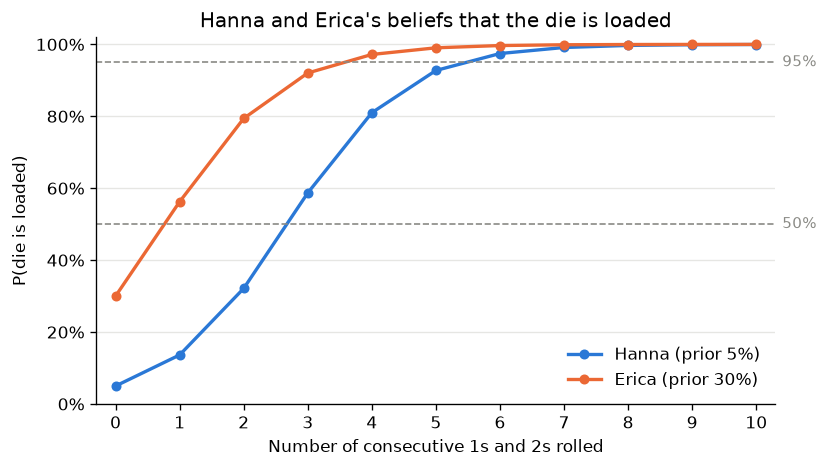

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, colour in [("Hanna", BLUE), ("Erica", ORANGE)]:
    ax.plot(beliefs["n"], beliefs[name], marker="o", markersize=5, lw=2, color=colour,
            label=f"{name} (prior {beliefs[name][0]:.0%})")
for level in (0.50, 0.95):
    ax.axhline(level, color=GREY, ls="--", lw=1)
    ax.text(1.01, level, f"{level:.0%}", va="center", color=GREY, fontsize=9,
            transform=ax.get_yaxis_transform())

ax.set(xlim=(-0.3, 10.3), ylim=(0, 1.02), xticks=range(11),
       xlabel="Number of consecutive 1s and 2s rolled", ylabel="P(die is loaded)",
       title="Hanna and Erica's beliefs that the die is loaded")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="y", color="#e6e6e3", lw=0.8)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

### (c) Hanna and Erica compared

Hanna and Erica learn from the rolls in exactly the same way: each 1 or 2 triples their odds. The
only difference is where they start. Erica's starting odds are about 8 times Hanna's, which puts her
roughly two rolls ahead. The gap between them first grows, to about 47 percentage points after 2
rolls, and then shrinks to almost nothing. Erica passes 95 % after 4 rolls and Hanna after 6. With
enough evidence, it stops mattering where they started.

### (d) How important are priors?

- **Priors decide how fast you get there, not where you end up.** With good evidence, people who
  start with different beliefs end up agreeing.
- **In the short run, priors matter a lot.** After 2 rolls Hanna and Erica are almost 50 percentage
  points apart, even though they saw exactly the same rolls.
- **Weak evidence lets priors matter for longer.** If each roll told us only a little, it would take
  many more rolls before they agreed. Evidence that settles the question, like rolling a 4, beats any
  prior straight away.
- **Someone who is 100 % (or 0 %) sure never changes their mind,** whatever they see. This is called
  Cromwell's rule, and it's why it's wise never to be completely certain.
- **Real people aren't perfect Bayesians.** They often update too little (conservatism), ignore base
  rates, and focus on evidence that fits what they already believe (confirmation bias). Because of
  this, people with different priors can drift further apart instead of agreeing.

## Question 2 – Base Rates

$C$ means the person is carrying something illegal, and $+$ means the search finds something. If
someone is carrying, the search finds it 99 % of the time: $P(+ \mid C) = 0.99$. If they're not
carrying, it still flags them 1 % of the time: $P(+ \mid \text{not } C) = 0.01$.

What we want to know is: if the search is positive, how likely is it that the person really is
carrying?

$$P(C \mid +) = \frac{P(+ \mid C)\,P(C)}{P(+ \mid C)\,P(C) + P(+ \mid \text{not } C)\,\bigl(1 - P(C)\bigr)}$$

In [5]:
def ppv(base_rate, sens=0.99, fpr=0.01):
    # P(C | +)
    return sens * base_rate / (sens * base_rate + fpr * (1 - base_rate))


def frequency_table(base_rate, population=1_000_000, sens=0.99, fpr=0.01):
    carrying = population * base_rate
    not_carrying = population - carrying
    table = pd.DataFrame({"Carrying": [sens * carrying, (1 - sens) * carrying],
                          "Not carrying": [fpr * not_carrying, (1 - fpr) * not_carrying]},
                         index=["Positive", "Negative"])
    table["Total"] = table.sum(axis=1)
    table.loc["Total"] = table.sum()
    return table.round().astype(int)

### (a) Base rate 1 in 10,000

Out of 1,000,000 people stopped:

In [6]:
frequency_table(1 / 10_000).style.format("{:,}")

,Carrying,Not carrying,Total
Positive,99,"9,999","10,098"
Negative,1,"989,901","989,902"
Total,100,"999,900","1,000,000"


In [7]:
print(f"P(C | +) = {100 * ppv(1 / 10_000):.2f} %")

P(C | +) = 0.98 %


About 10,100 people test positive, but only 99 of them are actually carrying something. That means
about 99 % of the people flagged are innocent. The reason is that so few people carry anything: 1 %
of almost a million innocent people (about 10,000) is far more than 99 % of the 100 people who are
guilty. So even though "99 % accurate" sounds good, a positive search says very little about whether
someone is guilty. Forgetting how rare something is, like this, is called base rate neglect.

### (b) Targeting young men, base rate 1 in 1,000

Out of 1,000,000 young men stopped:

In [8]:
frequency_table(1 / 1_000).style.format("{:,}")

,Carrying,Not carrying,Total
Positive,990,"9,990","10,980"
Negative,10,"989,010","989,020"
Total,"1,000","999,000","1,000,000"


In [9]:
print(f"P(C | +) = {100 * ppv(1 / 1_000):.1f} %")

P(C | +) = 9.0 %


With a base rate ten times higher, a positive search is right about nine times as often: 9.0 %
instead of 0.98 %. But about 91 % of the people flagged are still innocent, so the answer from (a)
doesn't change. The base rate would have to be around 1 in 100 before a positive search is right
half the time. Targeting one group also means all the mistakes land on that group: about 10,000
innocent young men for every million stopped. That raises real worries about discrimination and
trust in the police.

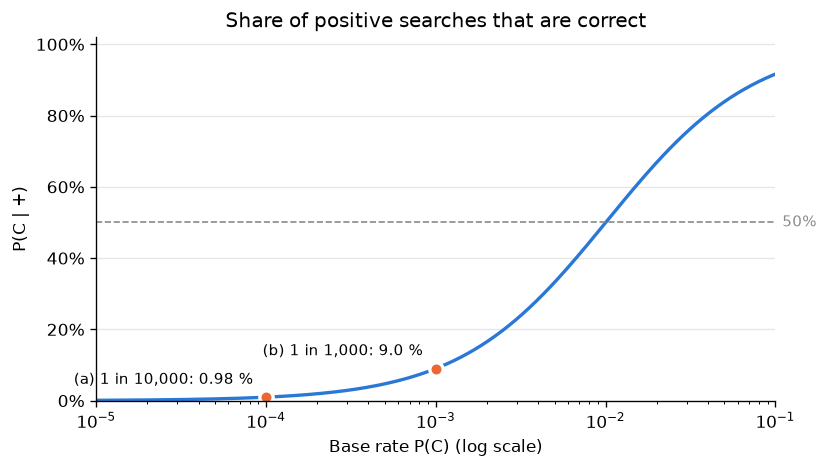

In [10]:
rates = np.logspace(-5, -1, 200)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rates, ppv(rates), color=BLUE, lw=2)
for rate, label, decimals in [(1 / 10_000, "(a) 1 in 10,000", 2), (1 / 1_000, "(b) 1 in 1,000", 1)]:
    ax.plot(rate, ppv(rate), "o", color=ORANGE, markersize=8, markeredgecolor="white", markeredgewidth=2)
    ax.annotate(f"{label}: {100 * ppv(rate):.{decimals}f} %", (rate, ppv(rate)), xytext=(-8, 8),
                textcoords="offset points", ha="right", fontsize=9)
ax.axhline(0.5, color=GREY, ls="--", lw=1)
ax.text(1.01, 0.5, "50%", va="center", color=GREY, fontsize=9, transform=ax.get_yaxis_transform())

ax.set_xscale("log")
ax.set(xlim=(1e-5, 1e-1), ylim=(0, 1.02), xlabel="Base rate P(C) (log scale)",
       ylabel="P(C | +)", title="Share of positive searches that are correct")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="y", color="#e6e6e3", lw=0.8)
plt.tight_layout()
plt.show()